# 04 — Exploração de Modelos (`SmolLM2-360M` vs. `Qwen 0.6B` vs. `1.7B`) e Quantização `Q4_K_M`

Documenta a seleção de família/porte de modelo e o estudo de quantização `F16` → `Q4_K_M` via `llama.cpp` em **GPU** (`-ngl 99`) e **CPU pura limitada a 2 threads** (`-dev none -ngl 0 -t 2`) para fundamentar o deploy econômico na AWS (`t3.medium`, 4 GiB RAM).

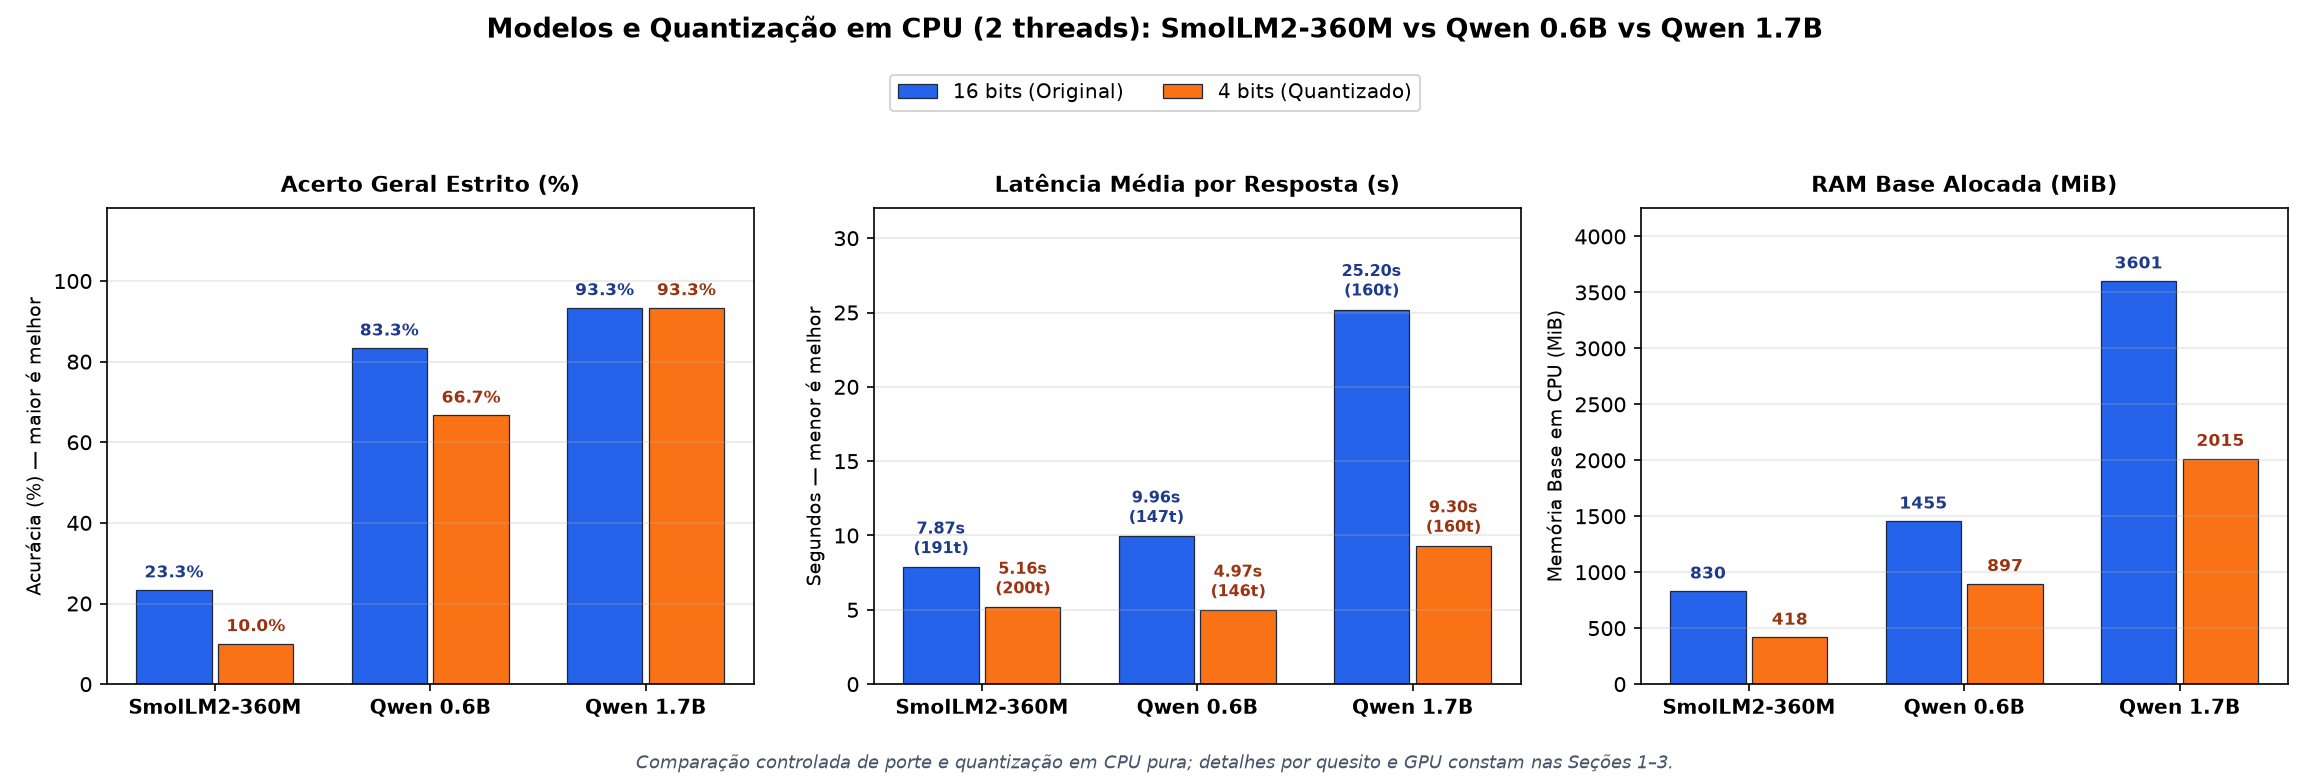

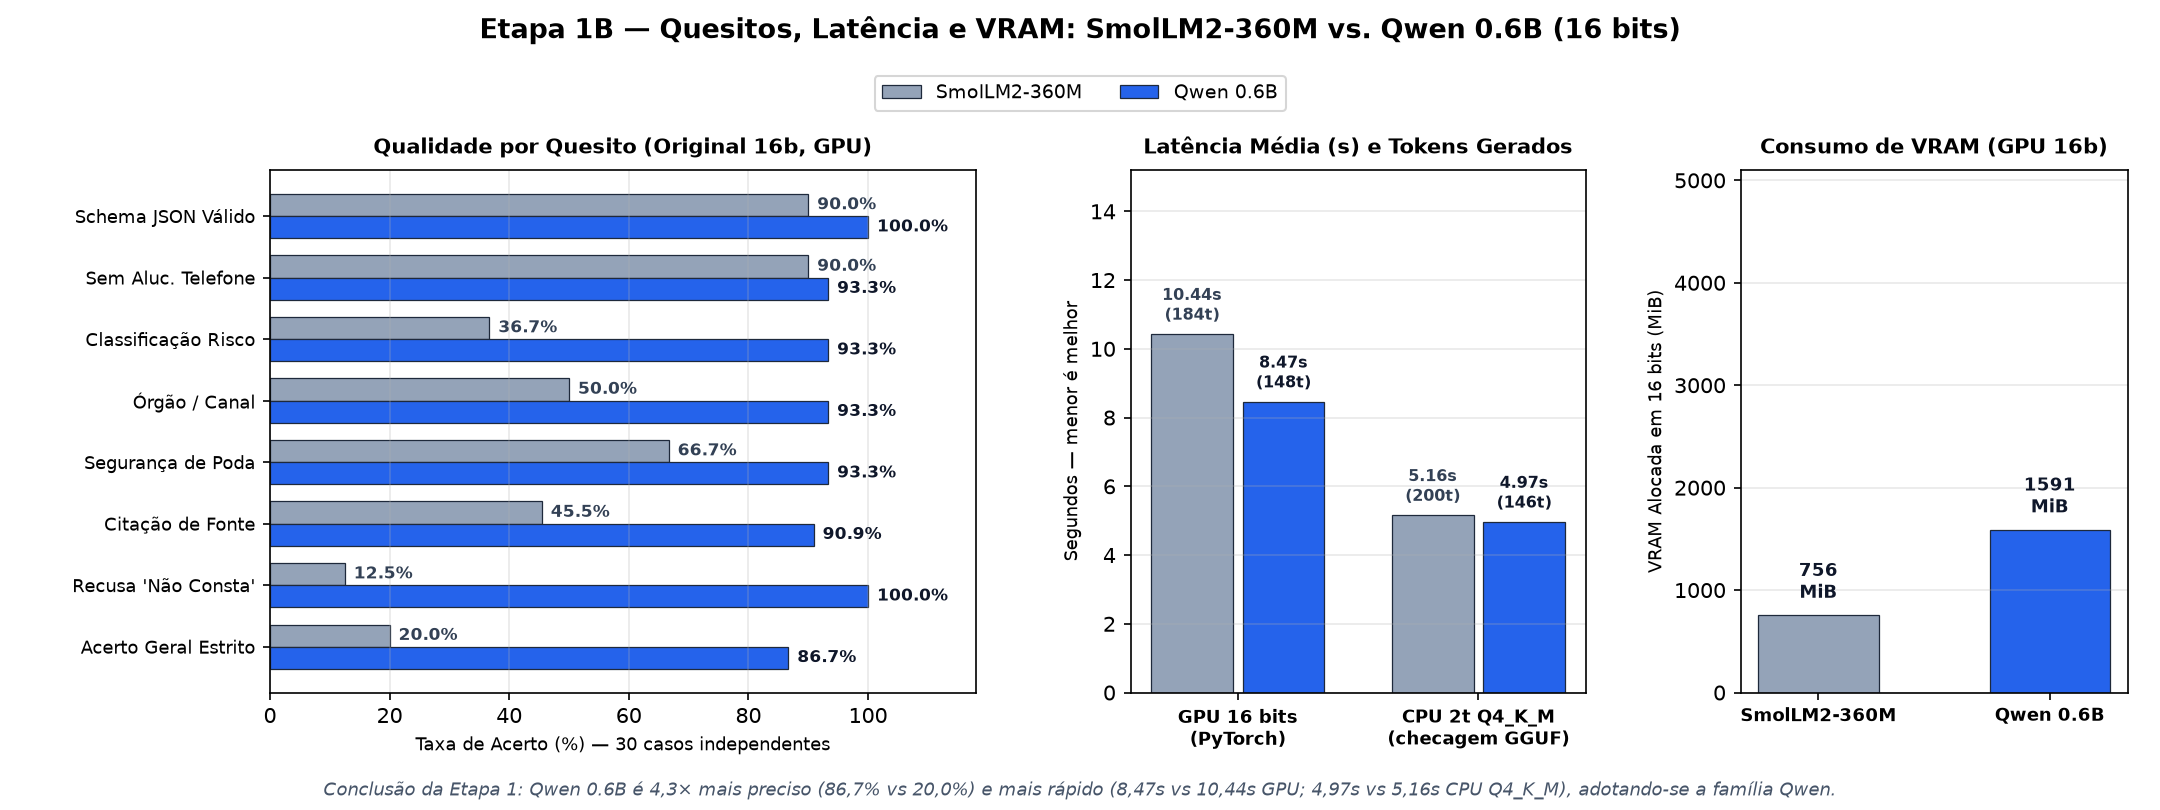

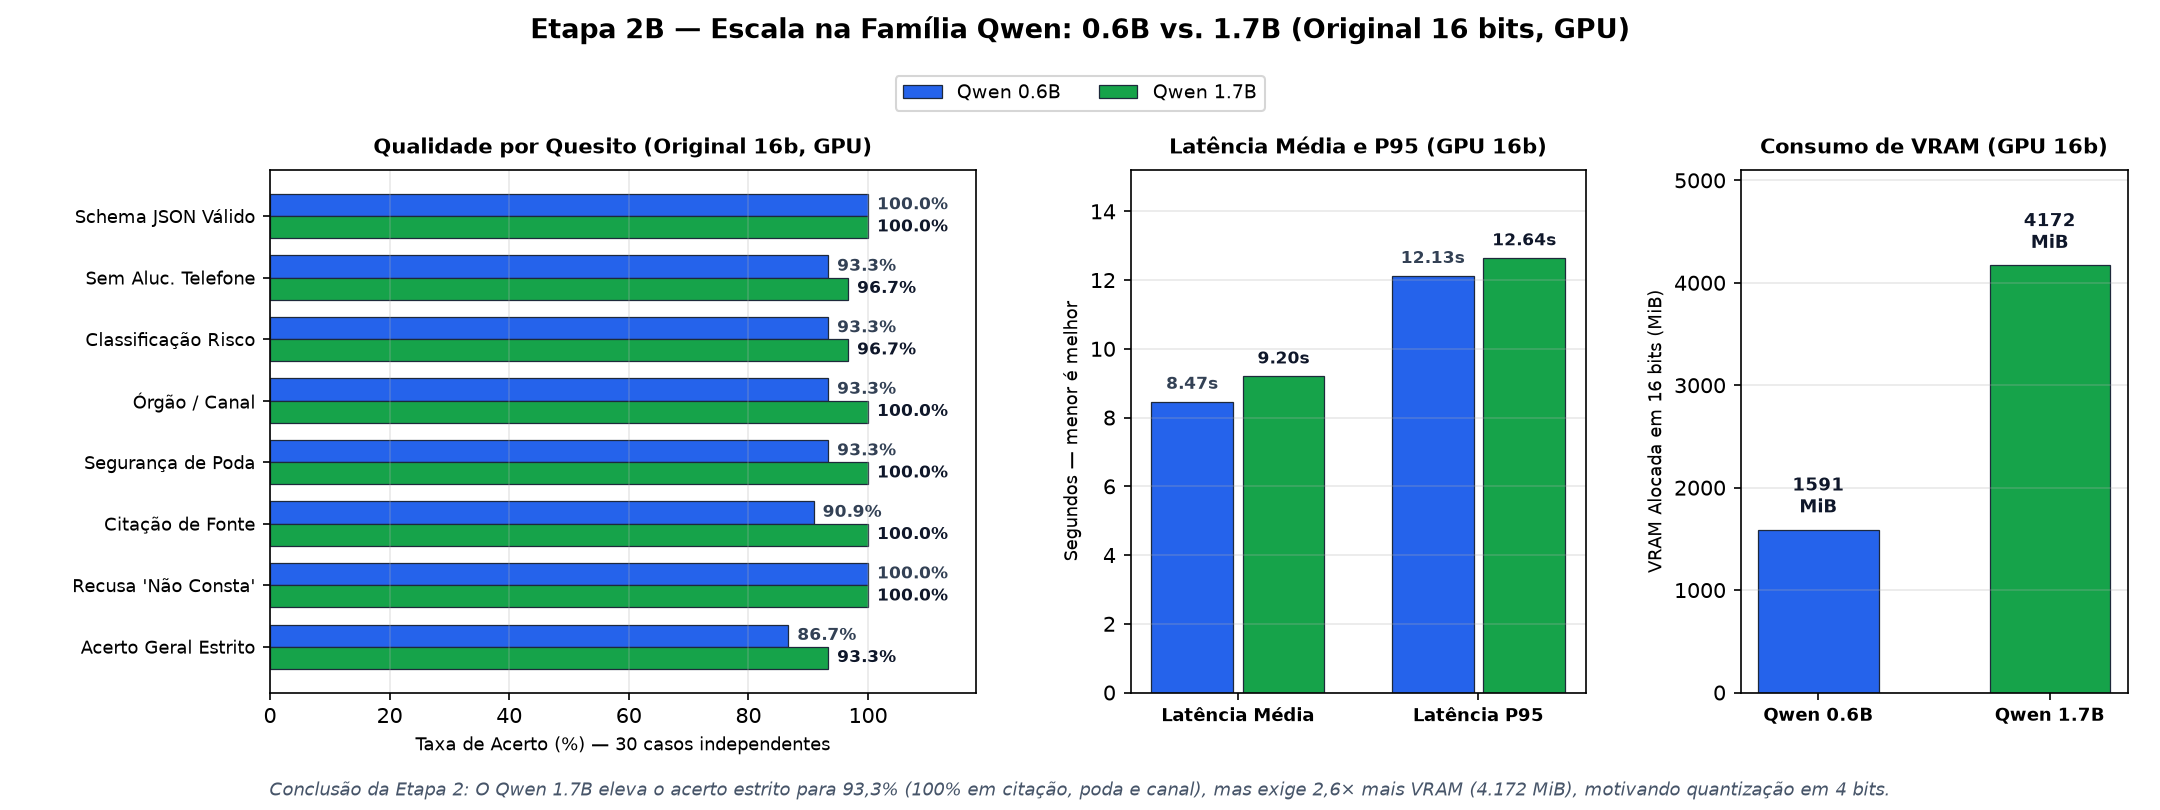

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.common import DIR_ASSETS, DIR_EVAL

REEXECUTAR_COMPARATIVOS = False  # True para regerar planilhas e gráficos consolidados
if REEXECUTAR_COMPARATIVOS or not (DIR_EVAL / 'placar_comparativo_modelos.csv').exists():
    from scripts.build_size_quant_comparison import main as run_comp
    from scripts.build_smol_vs_qwen_chart import main as run_smol
    run_comp()
    run_smol()

display(Image(filename=str(DIR_ASSETS / 'comparativo_smol360m_vs_qwen.png')))
display(Image(filename=str(DIR_ASSETS / 'exp_1_smol360m_vs_qwen06b.png')))
display(Image(filename=str(DIR_ASSETS / 'exp_2_qwen06b_vs_17b_escala.png')))

,modelo_base,formato_execucao,configuracao,tamanho_gguf_mib,memoria_execucao_mib,acuracia_geral_estrita,latencia_media_ms,latencia_p95_ms,tps_medio
0,Qwen 1.7B,Original 16 bits (GPU CUDA),1. Base sem contexto,NaN,NaN,0.2667,4549.1,5692.1,31.61
1,Qwen 1.7B,Original 16 bits (GPU CUDA),2. RAG simples,NaN,NaN,0.3333,5552.5,7251.3,31.27
2,Qwen 1.7B,Original 16 bits (GPU CUDA),"3. LoRA + RAG + Agente (Original 16 bits, GPU)",NaN,4172.0,0.9333,9203.8,12642.3,17.17
3,Qwen 0.6B,Original 16 bits (GPU CUDA),1. Base sem contexto,NaN,NaN,0.2667,3663.0,4489.9,32.69
4,Qwen 0.6B,Original 16 bits (GPU CUDA),2. RAG simples,NaN,NaN,0.2000,4680.2,5820.7,32.57
5,Qwen 0.6B,Original 16 bits (GPU CUDA),"3. LoRA + RAG + Agente (Original 16 bits, GPU)",NaN,1590.6,0.8667,8466.0,12126.2,17.49
6,Qwen 1.7B,GGUF 16b (GPU Vulkan),4g. LoRA + RAG + Agente (16b GPU),3287.6,5793.1,0.9000,1976.1,2705.1,81.05
7,Qwen 1.7B,GGUF 4b (GPU Vulkan),4g. LoRA + RAG + Agente (4b GPU),1056.1,3465.9,0.9000,1039.3,1372.8,155.52
8,Qwen 1.7B,GGUF 16b (CPU 2t),4c. LoRA + RAG + Agente (16b CPU 2t),3287.6,3600.9,0.9333,25197.7,34630.4,6.35
9,Qwen 1.7B,GGUF 4b (CPU 2t),"4. LoRA + RAG + Agente (Quantizado 4 bits, CPU...",1056.1,2015.0,0.9333,9298.6,12903.8,17.26


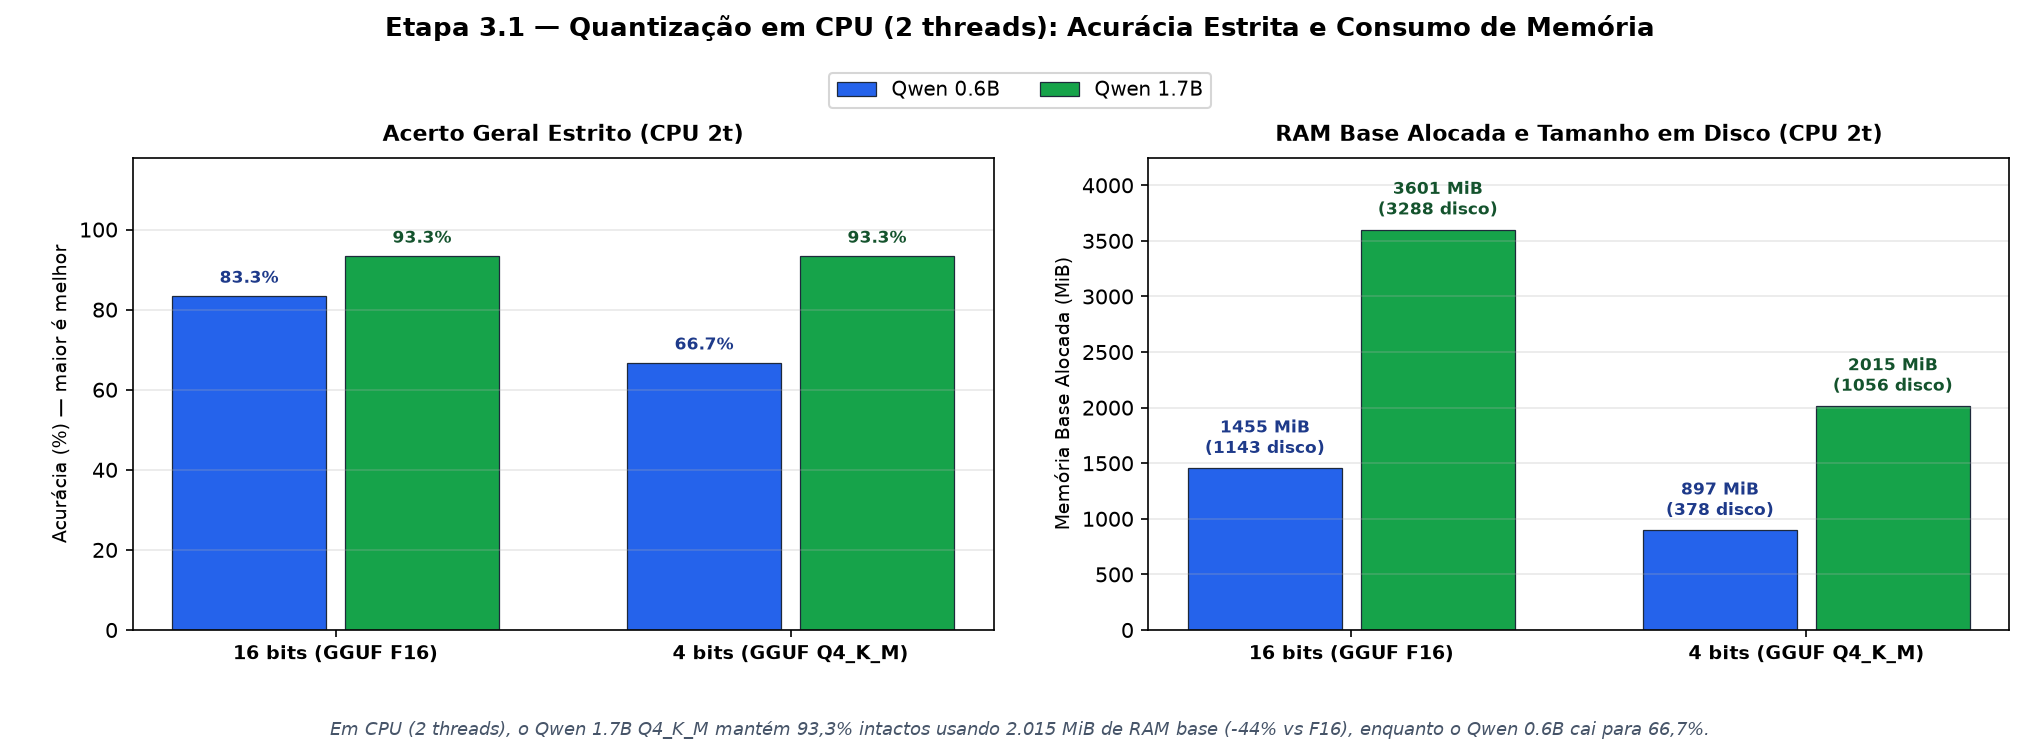

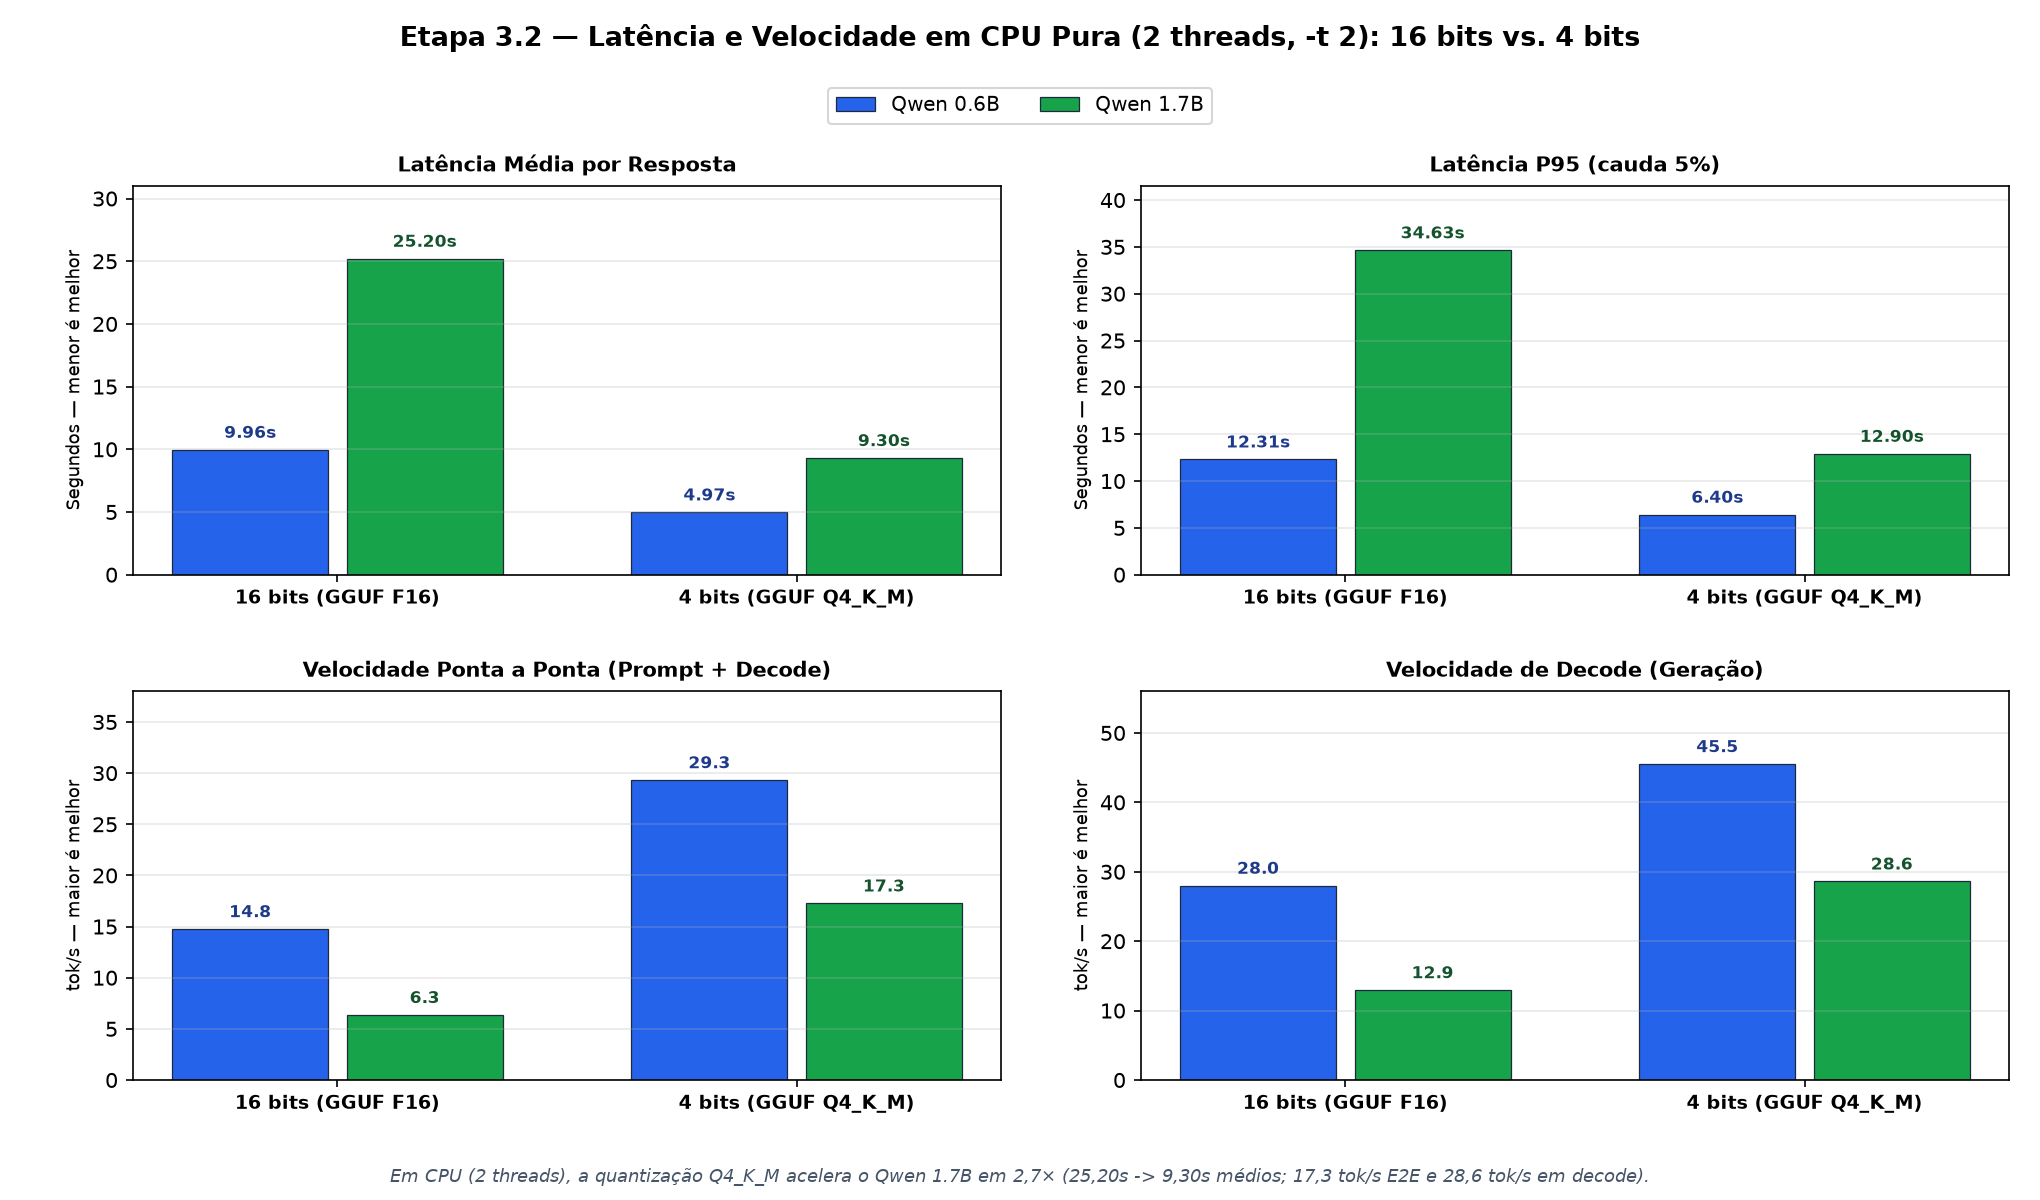

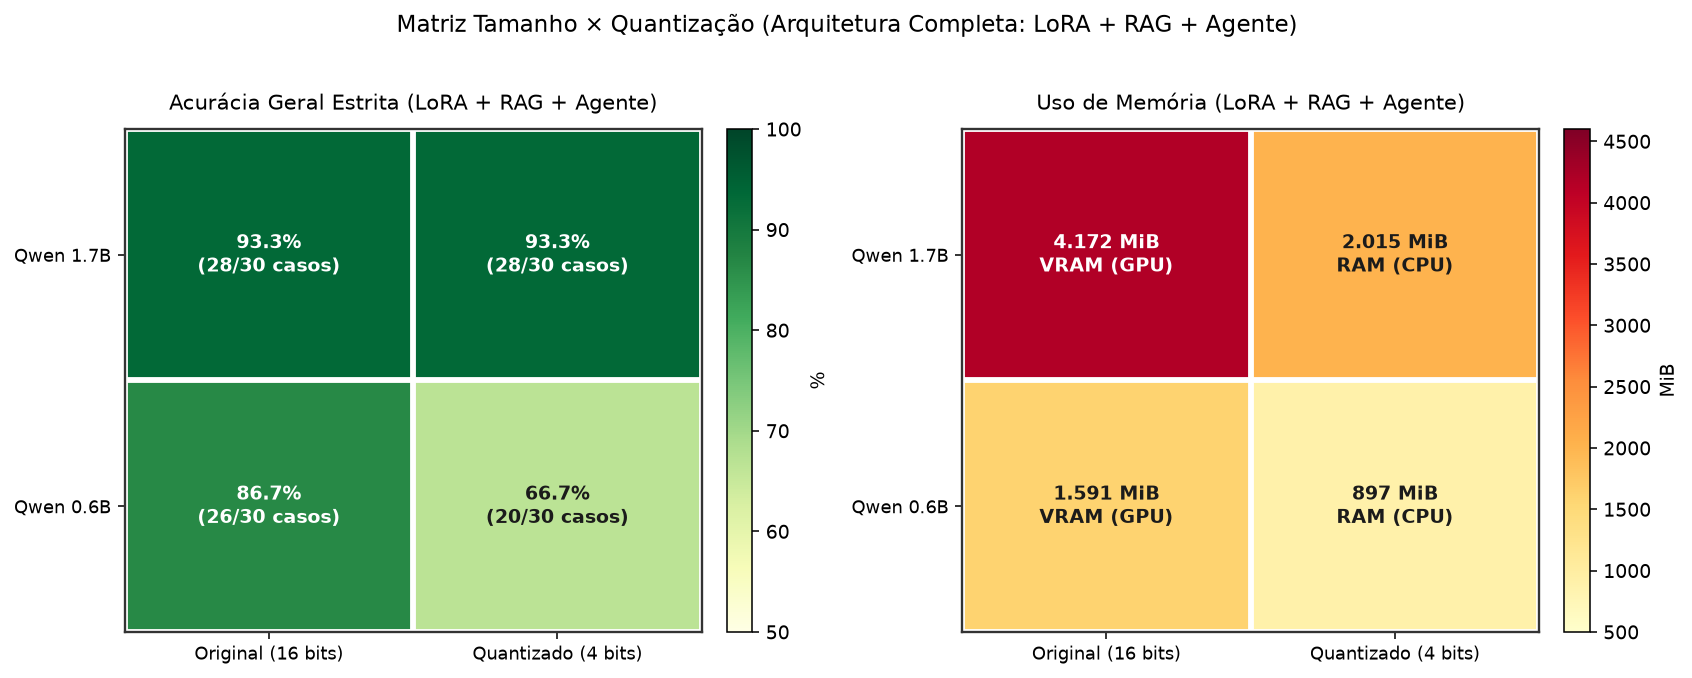

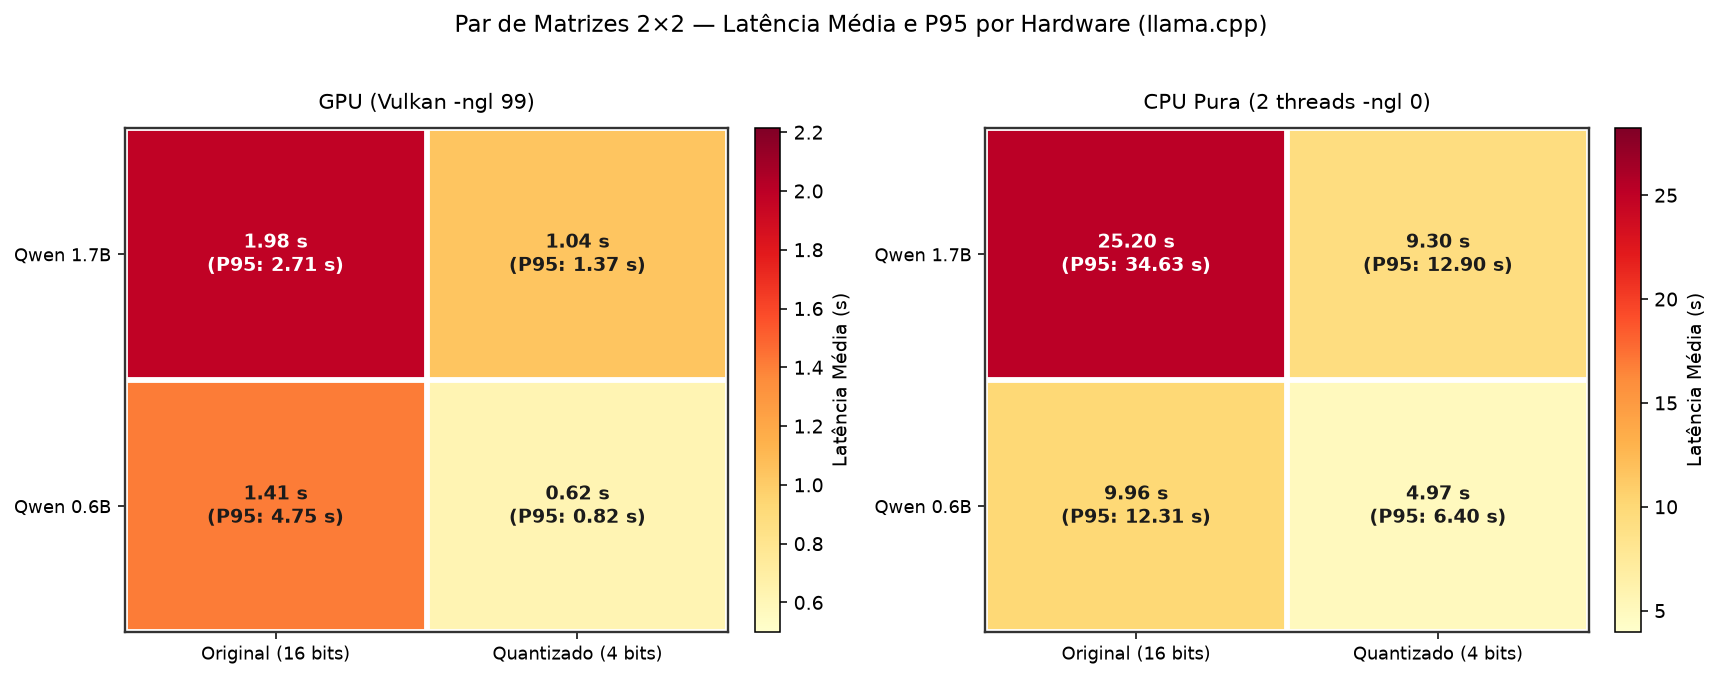

In [2]:
df_comp = pd.read_csv(DIR_EVAL / 'placar_comparativo_modelos.csv')
display(df_comp[['modelo_base', 'formato_execucao', 'configuracao', 'tamanho_gguf_mib', 'memoria_execucao_mib', 'acuracia_geral_estrita', 'latencia_media_ms', 'latencia_p95_ms', 'tps_medio']])
display(Image(filename=str(DIR_ASSETS / 'exp_3a_quantizacao_cpu_qualidade_memoria.png')))
display(Image(filename=str(DIR_ASSETS / 'exp_3b_quantizacao_cpu_velocidade.png')))
display(Image(filename=str(DIR_ASSETS / 'matriz_2x2_memoria_acuracia.png')))
display(Image(filename=str(DIR_ASSETS / 'matriz_2x2_latencia_gpu_cpu.png')))

### Decisão Final para Produção na Nuvem (`AWS EC2 t3.medium`)
- **`SmolLM2-360M` descartado:** `20,0%` em 16 bits (`10,0%` em Q4 CPU) e latência pior ou equivalente ao `Qwen 0.6B`.
- **`Qwen 1.7B Q4_K_M` aprovado para produção:** mantém **`93,3%` (`28/30`)** sem perda frente ao `F16` (`2.015,0 MiB` RAM base, `1.056,1 MiB` em disco, `9,30 s` em 2 threads CPU local / `~18,6 s` estimados em vCPU).
- Como o modelo de Visão Computacional (`segformer_v3_int8_dyn_matmul.onnx`) roda no navegador via `onnxruntime-web`, o **`Qwen 1.7B Q4_K_M`** cabe com folga na **`t3.medium` (4 GiB RAM)**.